In [1]:
import torch
import torch.nn as nn
torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10
# Chaque entrée contient 10 valeurs.
# La cible est la valeur immédiatement suivante.
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
# Un RNN attend : (nombre de séquences, longueur, nombre de variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique : début pour apprendre, fin pour tester.
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

Text(0, 0.5, 'y')

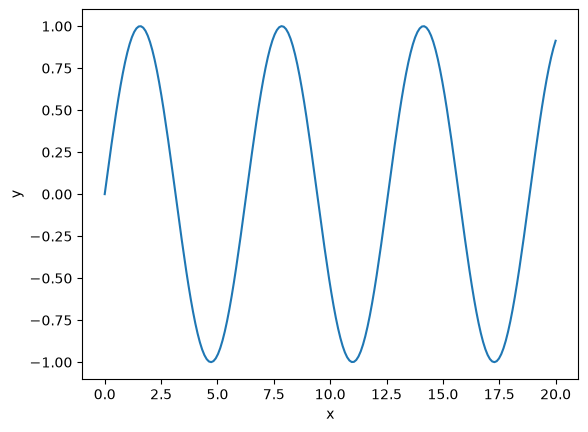

In [2]:
import matplotlib.pyplot as plt
plt.plot(periode, serie)
plt.xlabel("x")
plt.ylabel("y")

In [3]:
# --------------------------------------------------
# 2. Définir le modèle
# --------------------------------------------------

class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,     # Une valeur à chaque instant
            hidden_size=16,   # Une mémoire composée de 16 nombres
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Si aucun état initial n'est fourni, PyTorch utilise des zéros.
        etats, _ = self.rnn(x)

        # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]  # (nombre de séquences, 16)

        # Transformer la mémoire finale en une valeur prédite.
        return self.sortie(dernier_etat)


modele = SimpleRNN()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

In [4]:
# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()  # Effacer les anciens gradients
    perte.backward()       # Calculer les nouveaux gradients
    optimiseur.step()      # Mettre à jour les paramètres

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025

Erreur de test : 0.000028
Valeur réelle  : -0.3639
Valeur prédite : -0.3601


In [5]:
predictions.shape

torch.Size([40, 1])

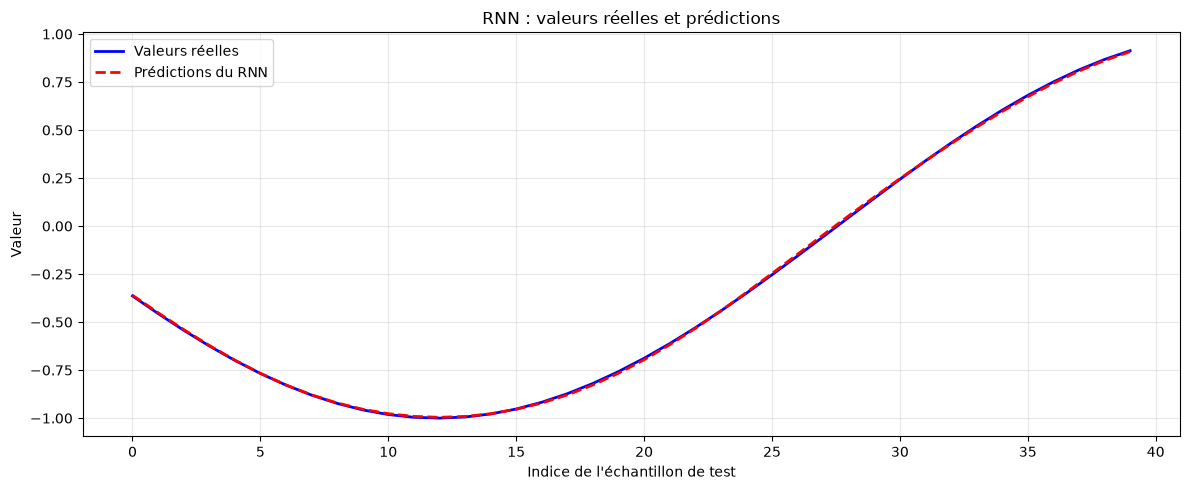

In [6]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du RNN",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme attendue : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


# --------------------------------------------------
# 2. Définir le modèle LSTM
# --------------------------------------------------

class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,     # Une variable à chaque instant
            hidden_size=16,   # 16 unités cachées
            num_layers=1,     # Une seule couche LSTM
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Sans états initiaux fournis, h₀ et c₀ sont mis à zéro.
        etats, (h_final, c_final) = self.lstm(x)

        # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]  # (nombre de séquences, 16)

        # Une prédiction par séquence
        return self.sortie(dernier_etat)


modele = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)


# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248
Epoch 150 | Erreur : 0.000043
Epoch 200 | Erreur : 0.000006
Epoch 250 | Erreur : 0.000004
Epoch 300 | Erreur : 0.000003

Erreur de test : 0.000003
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


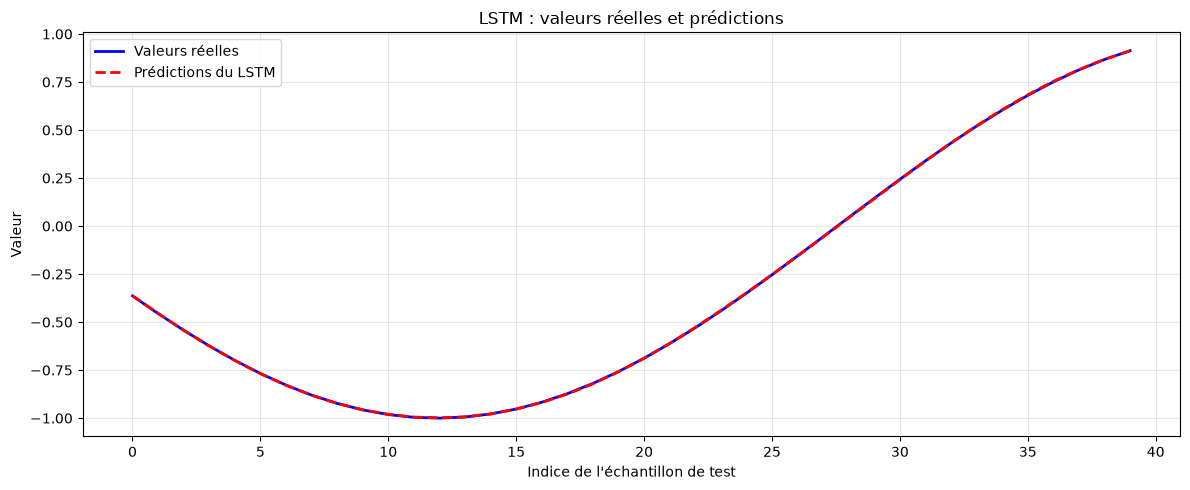

In [8]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du LSTM",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("LSTM : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


# --------------------------------------------------
# 2. Définir le modèle Transformer
# --------------------------------------------------

class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()

        dimension = 16

        # Transformer chaque valeur en un vecteur de 16 nombres.
        self.projection = nn.Linear(1, dimension)

        # Un vecteur appris pour chacune des 10 positions.
        self.positions = nn.Embedding(longueur_max, dimension)

        # Un bloc d'encodeur Transformer.
        couche = nn.TransformerEncoderLayer(
            d_model=dimension,       # Taille des représentations : 16
            nhead=2,                 # Deux têtes d'attention
            dim_feedforward=32,      # Taille interne du réseau feed-forward
            dropout=0.0,             # Désactivé pour simplifier l'exemple
            batch_first=True
        )

        self.encodeur = nn.TransformerEncoder(
            couche,
            num_layers=1
        )

        # Transformer la représentation finale en une prédiction.
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        # x : (B, 10, 1)
        longueur = x.size(1)

        # 1. Projection des valeurs
        x = self.projection(x)  # (B, 10, 16)

        # 2. Ajout de l'information de position
        indices = torch.arange(longueur, device=x.device)
        positions = self.positions(indices)  # (10, 16)

        x = x + positions.unsqueeze(0)  # (B, 10, 16)

        # 3. Mise en relation des valeurs par auto-attention
        representations = self.encodeur(x)  # (B, 10, 16)

        # 4. Récupérer la représentation de la dernière position
        derniere_position = representations[:, -1, :]  # (B, 16)

        # 5. Prédire la valeur suivante
        return self.sortie(derniere_position)  # (B, 1)


modele = MiniTransformer(longueur_max=longueur_sequence)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)


# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001504
Epoch 100 | Erreur : 0.000110
Epoch 150 | Erreur : 0.000026
Epoch 200 | Erreur : 0.000012
Epoch 250 | Erreur : 0.000007
Epoch 300 | Erreur : 0.000004

Erreur de test : 0.000006
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


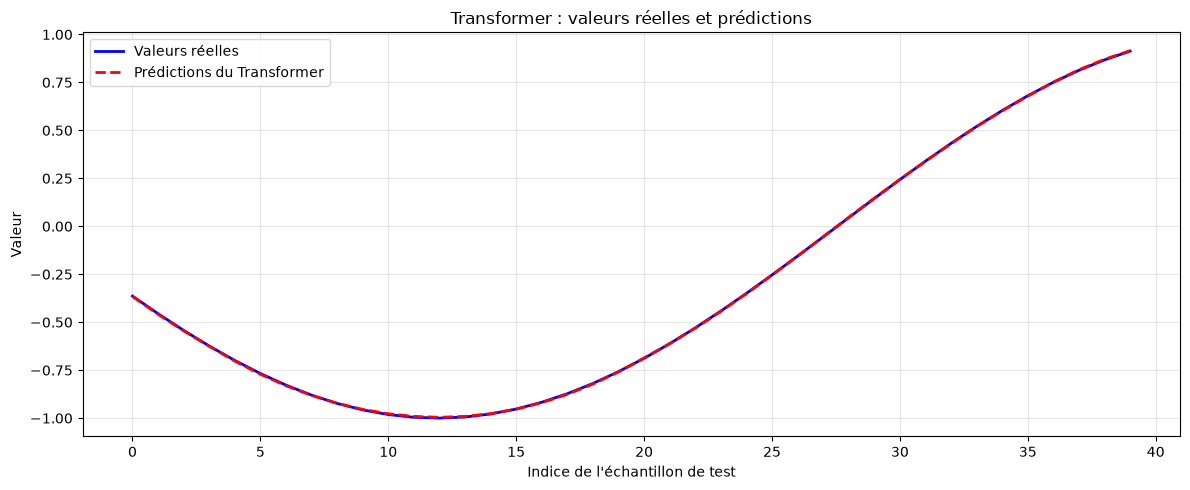

In [10]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du Transformer",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Transformer : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------

nom_modele = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForCausalLM.from_pretrained(nom_modele)

# GPT-2 ne possède pas de token de padding dédié.
tokenizer.pad_token = tokenizer.eos_token
modele.config.pad_token_id = tokenizer.pad_token_id

modele.eval()

# --------------------------------------------------
# 2. Transformer le texte en tokens
# --------------------------------------------------

# GPT-2 est principalement entraîné sur de l'anglais.
texte = "Artificial intelligence can help people"

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Dimensions de l'entrée :", entrees["input_ids"].shape)
# (1, nombre de tokens du texte)

# --------------------------------------------------
# 3. Générer la suite, un token après l'autre
# --------------------------------------------------

with torch.no_grad():
    sortie = modele.generate(
        **entrees,
        max_new_tokens=50,       # Générer au maximum 50 tokens
        do_sample=True,          # Tirage aléatoire des tokens
        temperature=0.8,         # Contrôler la diversité
        top_p=0.9,               # Limiter les candidats probables
        pad_token_id=tokenizer.pad_token_id
    )

# --------------------------------------------------
# 4. Reconvertir les tokens en texte
# --------------------------------------------------

texte_genere = tokenizer.decode(
    sortie[0],
    skip_special_tokens=True
)

print("\nTexte généré :")
print(texte_genere)

c:\5IADA\IA-GENERATIVE\TP4\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\5IADA\IA-GENERATIVE\TP4\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\DELL\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this arti

Dimensions de l'entrée : torch.Size([1, 6])

Texte généré :
Artificial intelligence can help people and organizations create jobs and build organizations, which in turn will spur growth and prosperity.

However, when a company becomes more complex, it's likely that its users will be less interested in technology. The companies that make the software that makes things


In [12]:
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------

nom_modele = "bert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForMaskedLM.from_pretrained(nom_modele)

modele.eval()

# --------------------------------------------------
# 2. Préparer un texte avec un token masqué
# --------------------------------------------------

texte = f"Rabat est la {tokenizer.mask_token} Maroc."

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Texte :", texte)
print("Dimensions de l'entrée :", entrees["input_ids"].shape)
# (1, nombre de tokens du texte)

# Repérer la position du masque dans la séquence
position_masque = (
    entrees["input_ids"][0] == tokenizer.mask_token_id
).nonzero(as_tuple=True)[0].item()

# --------------------------------------------------
# 3. Prédire le token masqué
# --------------------------------------------------

with torch.no_grad():
    sortie = modele(**entrees)

# sortie.logits : (1, nombre de tokens, taille du vocabulaire)
scores = sortie.logits[0, position_masque, :]

# Transformer les scores en probabilités
probabilites = torch.softmax(scores, dim=-1)

# Sélectionner les 5 tokens les plus probables
top_probabilites, top_indices = torch.topk(probabilites, k=5)

# --------------------------------------------------
# 4. Afficher les propositions
# --------------------------------------------------

print("\nPropositions de BERT :")

for probabilite, indice in zip(top_probabilites, top_indices):
    token = tokenizer.decode([indice.item()]).strip()

    phrase = texte.replace(tokenizer.mask_token, token)

    print(f"{probabilite.item():.2%} | {phrase}")

c:\5IADA\IA-GENERATIVE\TP4\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\DELL\.cache\huggingface\hub\models--bert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 202/202 [00:00<00:00, 282.01it/s]
[transformers] BertForMaskedLM LOAD REPOR

Texte : Rabat est la [MASK] Maroc.
Dimensions de l'entrée : torch.Size([1, 8])

Propositions de BERT :
42.90% | Rabat est la capitale Maroc.
20.66% | Rabat est la du Maroc.
6.23% | Rabat est la de Maroc.
3.46% | Rabat est la ville Maroc.
1.67% | Rabat est la Rabat Maroc.


In [13]:
# Exercice 1 : données UCI (téléchargement si nécessaire)
from pathlib import Path
from urllib.request import urlopen
import zipfile, shutil
path = Path('household_power_consumption.txt')
if not path.exists():
    with urlopen('https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip', timeout=120) as r, open('energy.zip','wb') as f:
        shutil.copyfileobj(r,f)
    with zipfile.ZipFile('energy.zip') as z:
        name = next(s for s in z.namelist() if s.endswith('household_power_consumption.txt'))
        with z.open(name) as src, path.open('wb') as dst:
            shutil.copyfileobj(src,dst)

In [14]:
import numpy as np
import pandas as pd
import torch
from torch.utils.data import TensorDataset, DataLoader

df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False,
)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
)

puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

# Puissance moyenne horaire : conserver les heures suffisamment renseignées.
horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

# Découpage chronologique : 70 % entraînement, 15 % validation, 15 % test.
n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

# Normalisation calculée uniquement sur l'entraînement.
moyenne = serie.iloc[:fin_train].mean()
ecart_type = serie.iloc[:fin_train].std()
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

# Une entrée contient 24 heures consécutives.
# Écarter les fenêtres comportant des valeurs manquantes.
fenetre = 24
X, y, dates_cibles = [], [], []

for i in range(fenetre, n):
    sequence = valeurs[i - fenetre:i]
    cible = valeurs[i]

    if np.isfinite(sequence).all() and np.isfinite(cible):
        X.append(sequence)
        y.append(cible)
        dates_cibles.append(i)

X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
dates_cibles = np.array(dates_cibles)

train_mask = dates_cibles < fin_train
val_mask = (dates_cibles >= fin_train) & (dates_cibles < fin_val)
test_mask = dates_cibles >= fin_val

train_loader = DataLoader(
    TensorDataset(X[train_mask], y[train_mask]),
    batch_size=64,
    shuffle=True,
)
val_loader = DataLoader(
    TensorDataset(X[val_mask], y[val_mask]),
    batch_size=64,
)
test_loader = DataLoader(
    TensorDataset(X[test_mask], y[test_mask]),
    batch_size=64,
)

In [15]:
# Exercice 1 : modèle EnergyTransformer
import copy
import torch.nn as nn
class EnergyTransformer(nn.Module):
    def __init__(self, fenetre=24):
        super().__init__()
        self.projection = nn.Linear(1,32)
        self.positions = nn.Embedding(fenetre,32)
        layer = nn.TransformerEncoderLayer(32,4,128,0.1,batch_first=True)
        self.encoder = nn.TransformerEncoder(layer,2)
        self.sortie = nn.Linear(32,1)
    def forward(self,x):
        x = self.projection(x) + self.positions(torch.arange(x.size(1),device=x.device))
        return self.sortie(self.encoder(x)[:,-1,:])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = EnergyTransformer().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(),lr=0.001)
def energy_loss(loader, training=False):
    model.train(training)
    total = 0
    with torch.set_grad_enabled(training):
        for xb,yb in loader:
            xb,yb = xb.to(device),yb.to(device)
            if training: optimizer.zero_grad()
            loss = criterion(model(xb),yb)
            if training:
                loss.backward()
                optimizer.step()
            total += loss.item()*len(xb)
    return total/len(loader.dataset)
best = float('inf')
for epoch in range(20):
    tr = energy_loss(train_loader,True)
    va = energy_loss(val_loader)
    if va < best:
        best = va
        best_state = copy.deepcopy(model.state_dict())
    print(f'{epoch+1}/20 | train={tr:.4f} | val={va:.4f}')
model.load_state_dict(best_state)

1/20 | train=0.4608 | val=0.4373
2/20 | train=0.4287 | val=0.4015
3/20 | train=0.4190 | val=0.3906
4/20 | train=0.4161 | val=0.3932
5/20 | train=0.4126 | val=0.4034
6/20 | train=0.4117 | val=0.3888
7/20 | train=0.4094 | val=0.3825
8/20 | train=0.4074 | val=0.3827
9/20 | train=0.4026 | val=0.3819
10/20 | train=0.4024 | val=0.3873
11/20 | train=0.4004 | val=0.3827
12/20 | train=0.4007 | val=0.3921
13/20 | train=0.3991 | val=0.3745
14/20 | train=0.3976 | val=0.3761
15/20 | train=0.3965 | val=0.3761
16/20 | train=0.3960 | val=0.3788
17/20 | train=0.3955 | val=0.3834
18/20 | train=0.3933 | val=0.3794
19/20 | train=0.3920 | val=0.3927
20/20 | train=0.3907 | val=0.3777


<All keys matched successfully>

Transformer MAE: 0.34319947984972077 RMSE: 0.4900366067784444
Persistance MAE: 0.38919810194269283 RMSE: 0.5883847071313123
Journalier MAE: 0.513277162006016 RMSE: 0.7638759711757404


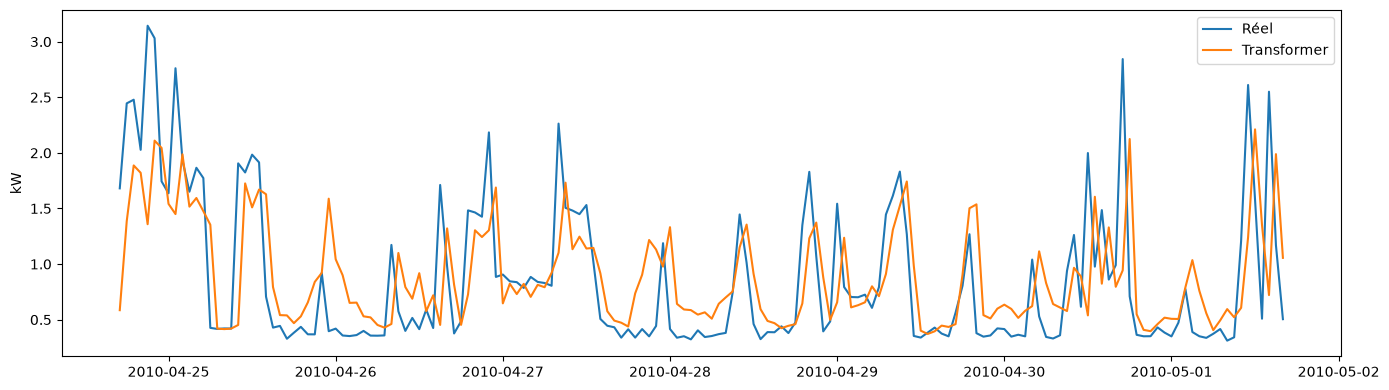

In [16]:
# Évaluation en kW et comparaison aux références
model.eval()
with torch.no_grad():
    pred = torch.cat([model(xb.to(device)).cpu() for xb,yb in test_loader]).flatten().numpy()
xt,yt = test_loader.dataset.tensors
reel = yt.flatten().numpy()*ecart_type+moyenne
pred = pred*ecart_type+moyenne
persistance = xt[:,-1,0].numpy()*ecart_type+moyenne
journalier = xt[:,0,0].numpy()*ecart_type+moyenne
for nom,p in [('Transformer',pred),('Persistance',persistance),('Journalier',journalier)]:
    print(nom, 'MAE:',np.abs(p-reel).mean(), 'RMSE:',np.sqrt(np.mean((p-reel)**2)))
dates = serie.index[dates_cibles[test_mask]]
# Sept jours calendaires consécutifs ; les heures manquantes restent visibles comme des trous.
index = pd.date_range(dates[0], periods=168, freq='h')
plt.figure(figsize=(14,4))
plt.plot(pd.Series(reel,index=dates).reindex(index),label='Réel')
plt.plot(pd.Series(pred,index=dates).reindex(index),label='Transformer')
plt.ylabel('kW'); plt.legend(); plt.tight_layout(); plt.show()

In [17]:
# Exercice 2 : corpus de caractères (exemple si aucun corpus fourni)
from pathlib import Path
import torch.nn.functional as F
if not Path('corpus.txt').exists():
    paragraphes = ["Le transformer utilise le mécanisme d'attention pour comprendre le contexte. Chaque caractère est représenté par un vecteur. Le modèle apprend à prédire le caractère suivant.", "Le traitement du langage naturel permet de comprendre et de générer du texte. Les réseaux de neurones apprennent à partir des exemples.", "Un modèle de langage analyse les relations entre les mots. Les données d'entraînement permettent d'ajuster les paramètres."]
    Path('corpus.txt').write_text(('\n'.join(paragraphes)+'\n')*30,encoding='utf-8')
texte = Path('corpus.txt').read_text(encoding='utf-8')
caracteres = sorted(set(texte)); stoi = {c:i for i,c in enumerate(caracteres)}; itos = dict(enumerate(caracteres))
tokens = torch.tensor([stoi[c] for c in texte],dtype=torch.long)
longueur=64
assert len(tokens)>longueur
class GPTBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.norm1=nn.LayerNorm(64); self.norm2=nn.LayerNorm(64)
        self.attn=nn.MultiheadAttention(64,4,batch_first=True)
        self.mlp=nn.Sequential(nn.Linear(64,256),nn.GELU(),nn.Linear(256,64))
    def forward(self,x):
        T=x.size(1)
        masque=torch.ones(T,T,dtype=torch.bool,device=x.device).triu(1)
        h=self.norm1(x)
        x=x+self.attn(h,h,h,attn_mask=masque,need_weights=False)[0]
        return x+self.mlp(self.norm2(x))
class MiniGPT(nn.Module):
    def __init__(self,v):
        super().__init__()
        self.tokens=nn.Embedding(v,64); self.positions=nn.Embedding(64,64)
        self.blocks=nn.Sequential(GPTBlock(),GPTBlock())
        self.head=nn.Sequential(nn.LayerNorm(64),nn.Linear(64,v))
    def forward(self,x):
        return self.head(self.blocks(self.tokens(x)+self.positions(torch.arange(x.size(1),device=x.device))))
gpt=MiniGPT(len(caracteres)).to(device)
opt=torch.optim.AdamW(gpt.parameters(),lr=0.001)
gpt.train()
for step in range(500):
    idx=torch.randint(len(tokens)-longueur,(32,))[:,None]+torch.arange(longueur)
    x,y=tokens[idx].to(device),tokens[idx+1].to(device)
    opt.zero_grad(); logits=gpt(x); loss=F.cross_entropy(logits.flatten(0,1),y.flatten()); loss.backward(); opt.step()
    if (step+1)%100==0: print(step+1,loss.item())

100 1.837120771408081
200 0.98164302110672
300 0.35017114877700806
400 0.14848800003528595
500 0.11127392202615738


In [18]:
# Vérification du masque causal et génération
gpt.eval()
with torch.no_grad():
    a=tokens[:64].unsqueeze(0).to(device); b=a.clone(); b[:,32:]=(b[:,32:]+1)%len(caracteres)
    assert torch.allclose(gpt(a)[:,:32],gpt(b)[:,:32],atol=1e-5,rtol=1e-5)
    for temperature in [0.5,1.0,1.5]:
        seq=tokens[:10].unsqueeze(0).to(device)
        for _ in range(200):
            scores=gpt(seq[:,-64:])[:,-1,:]/temperature
            seq=torch.cat([seq,torch.multinomial(scores.softmax(-1),1)],dim=1)
        print(temperature,''.join(itos[i] for i in seq[0].tolist()))

0.5 Le transformer utilise le mécanisme d'attention pour comprendre le contexte. Chaque caractère est eprésent par ud te comprende lacte caractère suivant.
Le traitemes.
Le tites trantux les leses mots. Les. donnne
1.0 Le transformer utilise le mécanisme d'atttent par pr dentrament d'ajutiter les les pécararamètis.
Le transforarmer utilise lise le mécanisme d'attention pomer plend à pChnd le contextè.
Le destes le rantiones a
1.5 Le transfor utir utiliseran le parmètrepend ère langade anaperemet direst s le moédèle de langalyse éntreèle pectésure lar suxte. Le te dones nneurones epar euntiod le caquestèt.fore le Le monncomprenns. Chte e


In [19]:
# Exercice 3 : mini-BERT, corpus de phrases distinctes
import re
PAD, UNK, CLS, SEP, MASK = 0,1,2,3,4
train_phrases = [f'{s} {v} {o}' for s in ['le chat','le chien','un enfant','la fille','le garçon'] for v in ['regarde','observe','cherche','aime'] for o in ['le jardin','la maison','un livre','la fenêtre','le soleil']]
val_phrases=['le chat observe le soleil','la fille cherche un livre','un enfant aime le jardin','le chien regarde la fenêtre']
train_phrases=[s for s in train_phrases if s not in val_phrases]
def mots(s): return re.findall(r"\w+",s.lower())
vocab=['[PAD]','[UNK]','[CLS]','[SEP]','[MASK]']+sorted({w for s in train_phrases for w in mots(s)})
word_to_id={w:i for i,w in enumerate(vocab)}
taille_vocabulaire=len(vocab)
def encoder(s):
    ids=[CLS]+[word_to_id.get(w,UNK) for w in mots(s)[:30]]+[SEP]
    return ids+[PAD]*(32-len(ids))
train_ids=torch.tensor([encoder(s) for s in train_phrases]); val_ids=torch.tensor([encoder(s) for s in val_phrases])
def corrompre(input_ids):
    ordinaires=input_ids>=5
    positions=(torch.rand(input_ids.shape,device=input_ids.device)<0.15)&ordinaires
    for i in range(len(input_ids)):
        if ordinaires[i].any() and not positions[i].any():
            choix=ordinaires[i].nonzero().flatten(); positions[i,choix[torch.randint(len(choix),(1,),device=input_ids.device)]]=True
    labels=input_ids.clone(); labels[~positions]=-100
    x=input_ids.clone(); r=torch.rand(x.shape,device=x.device)
    x[positions&(r<0.8)]=MASK
    rnd=positions&(r>=0.8)&(r<0.9)
    x[rnd]=torch.randint(5,taille_vocabulaire,(int(rnd.sum().item()),),device=x.device)
    return x,labels,positions
class MiniBERT(nn.Module):
    def __init__(self):
        super().__init__()
        self.tokens=nn.Embedding(taille_vocabulaire,64,padding_idx=PAD)
        self.positions=nn.Embedding(32,64)
        self.encoder=nn.TransformerEncoder(nn.TransformerEncoderLayer(64,4,256,batch_first=True),2,enable_nested_tensor=False)
        self.head=nn.Linear(64,taille_vocabulaire)
    def forward(self,x,padding):
        h=self.tokens(x)+self.positions(torch.arange(x.size(1),device=x.device))
        return self.head(self.encoder(h,src_key_padding_mask=padding))
bert=MiniBERT().to(device); opt=torch.optim.AdamW(bert.parameters(),lr=0.001)
critere=nn.CrossEntropyLoss(ignore_index=-100)
for epoch in range(30):
    bert.train()
    for ids in DataLoader(train_ids,batch_size=16,shuffle=True):
        ids=ids.to(device); x,labels,positions=corrompre(ids)
        opt.zero_grad(); logits=bert(x,ids==PAD); loss=critere(logits.reshape(-1,taille_vocabulaire),labels.reshape(-1)); loss.backward(); opt.step()
    if (epoch+1)%5==0: print(epoch+1,loss.item())

5 1.5277035236358643
10 1.1849913597106934
15 0.9717777371406555
20 0.7656989693641663
25 0.4501049518585205
30 0.6609257459640503


In [20]:
# Validation, propositions et test d'invariance au padding
bert.eval()
with torch.no_grad():
    ids=val_ids.to(device); x,labels,positions=corrompre(ids); padding=ids==PAD
    logits=bert(x,padding)
    print('Accuracy MLM:',(logits.argmax(-1)[positions]==labels[positions]).float().mean().item())
    for i,j in positions.nonzero().tolist():
        top=logits[i,j].topk(3).indices.tolist()
        print('Mot réel:',vocab[ids[i,j].item()],'| propositions:',[vocab[k] for k in top])
    alt=x.clone(); alt[padding]=5
    assert torch.allclose(logits[~padding],bert(alt,padding)[~padding],atol=1e-5,rtol=1e-5)

Accuracy MLM: 0.800000011920929
Mot réel: le | propositions: ['le', 'un', 'la']
Mot réel: le | propositions: ['le', 'un', 'la']
Mot réel: un | propositions: ['un', 'la', 'le']
Mot réel: enfant | propositions: ['enfant', 'livre', 'fille']
Mot réel: fenêtre | propositions: ['maison', 'fenêtre', 'livre']
